# Exploring the Mariana Trench region

In [1]:
import json, urllib.request, urllib.parse
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go

REGION = dict(west=140.0, east=148.0, south=9.0, north=15.0)
RESOLUTION = "med"

DATA_DIR = Path("data");    DATA_DIR.mkdir(exist_ok=True)
FIG_DIR  = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
CACHE = DATA_DIR / f"gmrt_{REGION['west']}_{REGION['east']}_{REGION['south']}_{REGION['north']}_{RESOLUTION}.asc"
print("Data will be cached at:", CACHE)

Data will be cached at: data/gmrt_140.0_148.0_9.0_15.0_med.asc


In [2]:
def fetch_gmrt(region, resolution, out_path):
    if out_path.exists():
        print(f"Using cached file ({out_path.stat().st_size/1e6:.1f} MB)")
        return out_path
    params = dict(minlongitude=region["west"], maxlongitude=region["east"],
                  minlatitude=region["south"], maxlatitude=region["north"],
                  format="esriascii", resolution=resolution, layer="topo")
    url = "https://www.gmrt.org/services/GridServer?" + urllib.parse.urlencode(params)
    print("Downloading:", url)
    req = urllib.request.Request(url, headers={"User-Agent": "unseen-seafloor"})
    try:
        with urllib.request.urlopen(req, timeout=300) as r:
            out_path.write_bytes(r.read())
    except Exception as e:
        raise RuntimeError(
            f"Download failed ({e}).\nManual fallback: open https://www.gmrt.org/GMRTMapTool/, draw the same box, "
            f"export as 'ESRI ASCII', and save the file as:\n  {out_path.resolve()}") from e
    print(f"Saved {out_path.stat().st_size/1e6:.1f} MB")
    return out_path

fetch_gmrt(REGION, RESOLUTION, CACHE)

Using cached file (22.4 MB)


PosixPath('data/gmrt_140.0_148.0_9.0_15.0_med.asc')

In [3]:
def read_esri_ascii(path):
    header = {}
    with open(path) as f:
        while True:
            pos = f.tell()
            line = f.readline()
            key = line.split()[0].lower() if line.strip() else ""
            if key and not key.lstrip("-").replace(".", "").isdigit():
                header[key] = float(line.split()[1])
            else:
                f.seek(pos)
                break
        z = np.loadtxt(f, dtype=np.float32)
    ncols, nrows = int(header["ncols"]), int(header["nrows"])
    z = z.reshape(nrows, ncols)
    dx = header.get("cellsize", header.get("dx"))
    dy = header.get("cellsize", header.get("dy"))
    x0 = header["xllcenter"] if "xllcenter" in header else header["xllcorner"] + dx / 2
    y0 = header["yllcenter"] if "yllcenter" in header else header["yllcorner"] + dy / 2
    nodata = header.get("nodata_value")
    if nodata is not None:
        z[z == nodata] = np.nan
    lon = x0 + dx * np.arange(ncols)
    lat = y0 + dy * np.arange(nrows)
    z = z[::-1]
    return lon, lat, z

lon, lat, z = read_esri_ascii(CACHE)
print(f"Grid: {z.shape[0]} rows (lat) x {z.shape[1]} cols (lon)")
print(f"Spacing: {np.diff(lon).mean()*60:.2f} arc-minutes")
print(f"Missing values: {np.isnan(z).sum()}")

Grid: 1365 rows (lat) x 1824 cols (lon)
Spacing: 0.26 arc-minutes
Missing values: 0


In [4]:
i, j = np.unravel_index(np.nanargmin(z), z.shape)
print(f"Deepest grid point: {z[i, j]:,.0f} m at {lat[i]:.3f}°N, {lon[j]:.3f}°E")
print(f"Shallowest point:   {np.nanmax(z):,.0f} m   (positive = above sea level, i.e. islands)")
print(f"Median depth:       {np.nanmedian(z):,.0f} m")
print(f"Share of area below 6,000 m (the 'hadal zone'): {(z < -6000).mean():.1%}")

Deepest grid point: -10,795 m at 11.971°N, 144.371°E
Shallowest point:   479 m   (positive = above sea level, i.e. islands)
Median depth:       -4,395 m
Share of area below 6,000 m (the 'hadal zone'): 13.9%


In [5]:
lat0 = np.deg2rad(lat.mean())
km_per_deg_lon = 111.32 * np.cos(lat0)
km_per_deg_lat = 110.57
dx_m = np.diff(lon).mean() * km_per_deg_lon * 1000
dy_m = np.diff(lat).mean() * km_per_deg_lat * 1000
print(f"Cell size: {dx_m:.0f} m (east-west) x {dy_m:.0f} m (north-south)")
print(f"Region size: {(lon[-1]-lon[0])*km_per_deg_lon:.0f} km x {(lat[-1]-lat[0])*km_per_deg_lat:.0f} km")

Cell size: 479 m (east-west) x 486 m (north-south)
Region size: 872 km x 663 km


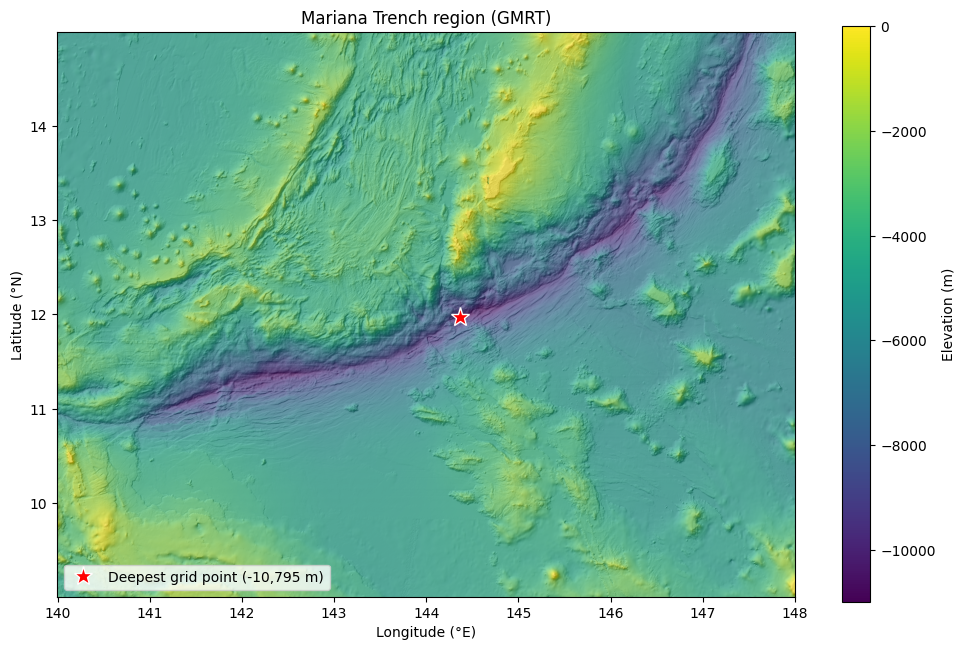

In [6]:
def hillshade(z, dx, dy, azimuth=315, altitude=45, exaggeration=1.0):
    dzdy, dzdx = np.gradient(z * exaggeration, dy, dx)
    n = np.stack([-dzdx, -dzdy, np.ones_like(z)])
    n /= np.linalg.norm(n, axis=0)
    az, alt = np.deg2rad(azimuth), np.deg2rad(altitude)
    L = np.array([np.sin(az) * np.cos(alt), np.cos(az) * np.cos(alt), np.sin(alt)])
    return np.clip(np.tensordot(L, n, axes=1), 0, 1)

shade = hillshade(np.nan_to_num(z, nan=np.nanmean(z)), dx_m, dy_m, exaggeration=3)

fig, ax = plt.subplots(figsize=(10, 7.5))
extent = [lon[0], lon[-1], lat[0], lat[-1]]
im = ax.imshow(z, extent=extent, origin="lower", cmap="viridis", vmin=-11000, vmax=0, aspect=1/np.cos(lat0))
ax.imshow(shade, extent=extent, origin="lower", cmap="gray", alpha=0.35, aspect=1/np.cos(lat0))
ax.plot(lon[j], lat[i], "r*", ms=14, mec="white", label=f"Deepest grid point ({z[i,j]:,.0f} m)")
cb = fig.colorbar(im, ax=ax, shrink=0.8); cb.set_label("Elevation (m)")
ax.set(xlabel="Longitude (°E)", ylabel="Latitude (°N)", title="Mariana Trench region (GMRT)")
ax.legend(loc="lower left")
fig.tight_layout(); fig.savefig(FIG_DIR / "01_map.png", dpi=200)
plt.show()

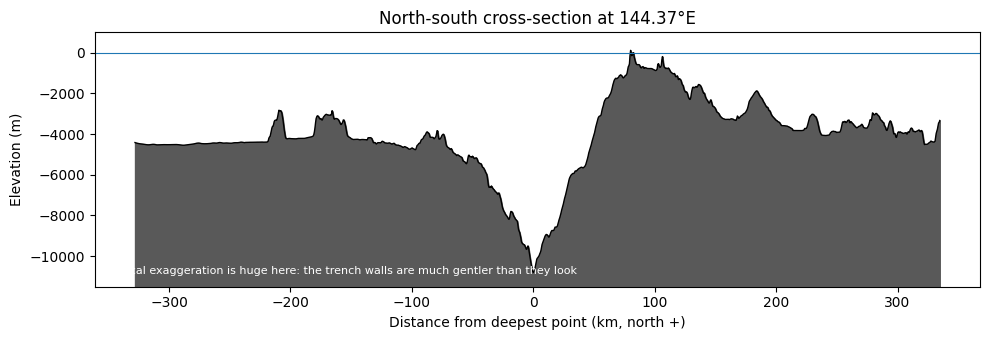

In [7]:
profile = z[:, j]
dist_km = (lat - lat[i]) * km_per_deg_lat

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.fill_between(dist_km, profile, -11500, color="0.35")
ax.plot(dist_km, profile, "k", lw=1)
ax.axhline(0, color="tab:blue", lw=0.8)
ax.set(xlabel="Distance from deepest point (km, north +)", ylabel="Elevation (m)",
       title=f"North-south cross-section at {lon[j]:.2f}°E", ylim=(-11500, 1000))
ax.text(0.01, 0.05, "Vertical exaggeration is huge here: the trench walls are much gentler than they look",
        transform=ax.transAxes, fontsize=8, color="white")
fig.tight_layout(); fig.savefig(FIG_DIR / "01_profile.png", dpi=200)
plt.show()

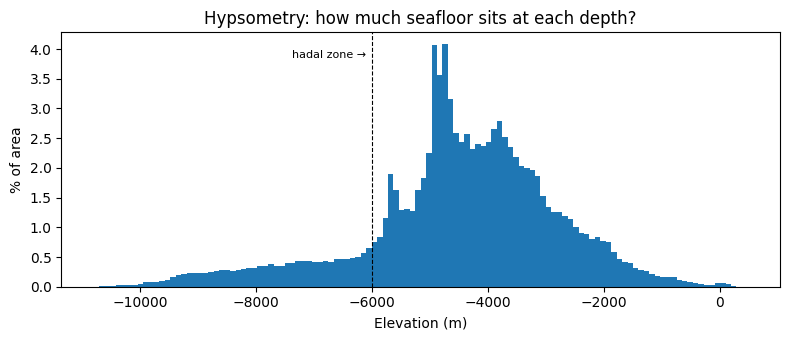

In [8]:
weights = np.repeat(np.cos(np.deg2rad(lat))[:, None], z.shape[1], axis=1)
ok = ~np.isnan(z)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(z[ok], bins=120, weights=weights[ok] / weights[ok].sum() * 100, color="tab:blue")
ax.axvline(-6000, color="k", ls="--", lw=0.8); ax.text(-6100, ax.get_ylim()[1]*0.9, "hadal zone →", ha="right", fontsize=8)
ax.set(xlabel="Elevation (m)", ylabel="% of area", title="Hypsometry: how much seafloor sits at each depth?")
fig.tight_layout(); fig.savefig(FIG_DIR / "01_hypsometry.png", dpi=200)
plt.show()

In [9]:
step = max(1, max(z.shape) // 350)
zs, lons, lats = z[::step, ::step], lon[::step], lat[::step]
VERT_EXAG = 8

fig3d = go.Figure(go.Surface(
    x=lons, y=lats, z=zs, colorscale="Viridis", cmin=-11000, cmax=0,
    colorbar=dict(title="m"),
    lighting=dict(ambient=0.45, diffuse=0.8, roughness=0.6, specular=0.15),
    hovertemplate="%{y:.2f}°N, %{x:.2f}°E<br>%{z:,.0f} m<extra></extra>"))
width_km = (lon[-1] - lon[0]) * km_per_deg_lon
height_km = (lat[-1] - lat[0]) * km_per_deg_lat
fig3d.update_layout(
    title=f"Mariana Trench in 3D (vertical exaggeration x{VERT_EXAG})",
    scene=dict(xaxis_title="Lon (°E)", yaxis_title="Lat (°N)", zaxis_title="Elevation (m)",
               aspectmode="manual",
               aspectratio=dict(x=1, y=height_km / width_km, z=VERT_EXAG * 12 / width_km),
               camera=dict(eye=dict(x=-1.2, y=-1.6, z=0.9))),
    height=700, margin=dict(l=0, r=0, t=40, b=0))
fig3d.write_html(FIG_DIR / "01_trench_3d.html", include_plotlyjs="cdn")
fig3d.show()